# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Rafinara Ardhani Abhinaya
- **Email:** rafinaraardhani@gmail.com
- **ID Dicoding:** DS284B6Y1484

## Menentukan Pertanyaan Bisnis

**Konteks:** Dataset ini berisi transaksi marketplace e-commerce di Brasil (Olist) dengan rentang waktu Sep 2016 - Okt 2018. Karena data 2016 sangat sedikit dan data akhir 2018 tidak lengkap, analisis dibatasi pada **Januari 2017 - Agustus 2018**. Seluruh analisis hanya memakai pesanan berstatus `delivered`.

**Pertanyaan 1 (Revenue)**
> Kategori produk apa saja yang masuk 10 besar berdasarkan total revenue (jumlah `price`, di luar ongkos kirim) dan berapa persen kontribusinya terhadap total revenue pesanan *delivered* selama Januari 2017 - Agustus 2018?

- *Specific*: fokus pada kategori produk dan revenue pesanan delivered.
- *Measurable*: total revenue (R$) dan persentase kontribusi.
- *Action-oriented*: hasilnya menentukan kategori mana yang diprioritaskan untuk promosi dan stok.
- *Relevant*: revenue adalah metrik utama kinerja marketplace.
- *Time-bound*: Januari 2017 - Agustus 2018.

**Pertanyaan 2 (Logistik & Kepuasan Pelanggan)**
> Di negara bagian (*state*) mana persentase pesanan terlambat (tanggal tiba > estimasi) paling tinggi, dan berapa selisih rata-rata *review score* antara pesanan tepat waktu dan terlambat pada pesanan delivered Januari 2017 - Agustus 2018?

- *Specific*: keterlambatan pengiriman per state dan dampaknya ke review score.
- *Measurable*: persentase pesanan terlambat, rata-rata review score, selisih skor.
- *Action-oriented*: menentukan wilayah yang perlu perbaikan logistik atau penyesuaian estimasi pengiriman.
- *Relevant*: kepuasan pelanggan berpengaruh langsung ke retensi dan reputasi.
- *Time-bound*: Januari 2017 - Agustus 2018.

## Import Semua Packages/Library yang Digunakan

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## Data Wrangling

### Gathering Data

Letakkan file CSV dataset di folder `data/`. Hanya 6 tabel yang dibutuhkan untuk menjawab kedua pertanyaan.

In [2]:
DATA_PATH = "data"

customers_df = pd.read_csv(os.path.join(DATA_PATH, "customers_dataset.csv"))
orders_df = pd.read_csv(os.path.join(DATA_PATH, "orders_dataset.csv"))
order_items_df = pd.read_csv(os.path.join(DATA_PATH, "order_items_dataset.csv"))
products_df = pd.read_csv(os.path.join(DATA_PATH, "products_dataset.csv"))
category_df_trans = pd.read_csv(os.path.join(DATA_PATH, "product_category_name_translation.csv"))
reviews_df = pd.read_csv(os.path.join(DATA_PATH, "order_reviews_dataset.csv"))

orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


**Insight (Gathering Data):**
- Data tersebar di beberapa tabel relasional: 99.441 pelanggan/pesanan, 112.650 item pesanan, 32.951 produk, dan 99.224 review. Tabel `orders` menjadi pusat, dihubungkan lewat `order_id`, `customer_id`, dan `product_id`.
- Kolom tanggal masih terbaca sebagai teks (`object`), sehingga perlu dikonversi sebelum dihitung.

### Assessing Data

**Tujuan & teknik:** menilai kualitas data sebelum dianalisis. Teknik yang dipakai: `shape` (ukuran data), `duplicated()` (duplikasi), `isna().sum()` (missing value), `info()` (tipe data), `value_counts()` (sebaran status), serta `describe()` (ringkasan statistik untuk mendeteksi outlier).

In [3]:
tables = {
    "customers": customers_df, "orders": orders_df, "order_items": order_items_df,
    "products": products_df, "category_translation": category_df_trans, "reviews": reviews_df,
}
for name, df in tables.items():
    print(f"{name:22s} shape={df.shape}  duplikat={df.duplicated().sum()}  total_missing={df.isna().sum().sum()}")

customers              shape=(99441, 5)  duplikat=0  total_missing=0
orders                 shape=(99441, 8)  duplikat=0  total_missing=4908
order_items            shape=(112650, 7)  duplikat=0  total_missing=0
products               shape=(32951, 9)  duplikat=0  total_missing=2448
category_translation   shape=(71, 2)  duplikat=0  total_missing=0


reviews                shape=(99224, 7)  duplikat=0  total_missing=145903


In [4]:
# Missing value per kolom (hanya kolom yang bermasalah)
for name in ["orders", "products", "reviews"]:
    miss = tables[name].isna().sum()
    print(f"--- {name} ---")
    print(miss[miss > 0], "\n")

--- orders ---
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64 

--- products ---
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64 

--- reviews ---
review_comment_title      87656
review_comment_message    58247
dtype: int64 



In [5]:
orders_df.info()
print("\nDistribusi status pesanan:")
print(orders_df["order_status"].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB

Distribusi status pesanan:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [6]:
# Cek konsistensi: pesanan delivered tapi tanggal tiba kosong
delivered_mask = orders_df["order_status"] == "delivered"
print("Delivered tanpa tanggal tiba:", orders_df.loc[delivered_mask, "order_delivered_customer_date"].isna().sum())

# Cek nilai tidak valid: tanggal tiba lebih awal dari tanggal pembelian
tmp = orders_df.copy()
for c in ["order_purchase_timestamp", "order_delivered_customer_date"]:
    tmp[c] = pd.to_datetime(tmp[c])
print("Tanggal tiba < tanggal beli:", (tmp["order_delivered_customer_date"] < tmp["order_purchase_timestamp"]).sum())

# Cek duplikasi review per order
print("Order dengan lebih dari 1 review:", (reviews_df["order_id"].value_counts() > 1).sum())

# Cek outlier waktu pengiriman (hari)
tmp["delivery_time"] = (tmp["order_delivered_customer_date"] - tmp["order_purchase_timestamp"]).dt.days
print(tmp["delivery_time"].describe())

Delivered tanpa tanggal tiba: 8
Tanggal tiba < tanggal beli: 0
Order dengan lebih dari 1 review: 547
count    96476.000000
mean        12.094086
std          9.551746
min          0.000000
25%          6.000000
50%         10.000000
75%         15.000000
max        209.000000
Name: delivery_time, dtype: float64


**Insight (masalah yang ditemukan dan rencana pembersihan):**

| No | Masalah (hasil assessing) | Tabel | Tindakan di tahap Cleaning |
|----|---------------------------|-------|----------------------------|
| 1 | *Missing value*: `product_category_name` kosong pada 610 produk | products | Isi dengan `unknown`, lalu terjemahkan ke bahasa Inggris |
| 2 | *Missing value* pada kolom tanggal: approved 160, carrier 1.783, delivered 2.965 (sebagian besar pesanan non-delivered) | orders | Filter hanya `delivered` dan buang baris tanpa tanggal tiba |
| 3 | *Inconsistent value*: 8 pesanan berstatus `delivered` tetapi tanggal tiba kosong | orders | Buang baris tersebut |
| 4 | *Inaccurate value*: tipe data tanggal masih `object`/teks | orders | Konversi ke `datetime` |
| 5 | *Duplicate data*: 547 `order_id` memiliki lebih dari satu review | reviews | Simpan review terakhir per order |
| 6 | *Outlier* waktu pengiriman: maksimum 209 hari, sedangkan median 10 hari | orders | Dipertahankan karena kejadian nyata, tetapi dicatat sebagai keterbatasan |

### Cleaning Data

**Tujuan & teknik cleaning:** memastikan hanya data valid yang dianalisis. Tanggal dikonversi dengan `pd.to_datetime` agar bisa dihitung selisihnya; filter `delivered` dan `dropna` dipakai karena keterlambatan hanya bisa dihitung pada pesanan yang sudah tiba; filter periode dipakai karena data 2016 dan akhir 2018 tidak lengkap.

In [7]:
# 1. Konversi tipe data tanggal
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
for c in date_cols:
    orders_df[c] = pd.to_datetime(orders_df[c])

# 2. Hanya pesanan delivered dan punya tanggal tiba
orders_df = orders_df[orders_df["order_status"] == "delivered"].dropna(subset=["order_delivered_customer_date"])

# 3. Buang tanggal tidak valid (tiba sebelum dibeli)
orders_df = orders_df[orders_df["order_delivered_customer_date"] >= orders_df["order_purchase_timestamp"]]

# 4. Batasi periode analisis
orders_df = orders_df[(orders_df["order_purchase_timestamp"] >= "2017-01-01") &
                      (orders_df["order_purchase_timestamp"] < "2018-09-01")]

print("Jumlah pesanan setelah cleaning:", orders_df.shape[0])

Jumlah pesanan setelah cleaning: 96203


In [8]:
# 5. Kategori produk: isi missing & terjemahkan
products_df["product_category_name"] = products_df["product_category_name"].fillna("unknown")
products_df = products_df.merge(category_df_trans, on="product_category_name", how="left")
products_df["product_category_name_english"] = (
    products_df["product_category_name_english"].fillna(products_df["product_category_name"])
)

# 6. Review: satu review (terbaru) per order
reviews_df["review_answer_timestamp"] = pd.to_datetime(reviews_df["review_answer_timestamp"])
reviews_df = (reviews_df.sort_values("review_answer_timestamp")
                        .drop_duplicates(subset="order_id", keep="last"))

# 7. Hapus duplikat lain bila ada
for df in (customers_df, orders_df, order_items_df, products_df):
    df.drop_duplicates(inplace=True)

print("Review unik per order:", reviews_df["order_id"].is_unique)
print("Missing kategori setelah cleaning:", products_df["product_category_name_english"].isna().sum())

Review unik per order: True
Missing kategori setelah cleaning: 0


**Tujuan & teknik:** `merge` (join) menggabungkan tabel relasional menjadi satu dataframe analisis. Digunakan `inner join` pada `orders` agar hanya pesanan valid yang tersisa, dan `left join` untuk atribut tambahan. Fitur turunan dibuat: `delivery_time_days` (lama kirim), `delivery_delay_days` (selisih tiba vs estimasi), dan `is_late` (penanda terlambat).

In [9]:
# 8. Gabungkan seluruh tabel menjadi satu dataframe analisis
main_df = (
    order_items_df
    .merge(orders_df[["order_id", "customer_id", "order_purchase_timestamp",
                      "order_delivered_customer_date", "order_estimated_delivery_date"]],
           on="order_id", how="inner")
    .merge(customers_df[["customer_id", "customer_state"]], on="customer_id", how="left")
    .merge(products_df[["product_id", "product_category_name_english"]], on="product_id", how="left")
    .merge(reviews_df[["order_id", "review_score"]], on="order_id", how="left")
)
main_df["product_category_name_english"] = main_df["product_category_name_english"].fillna("unknown")

# Fitur turunan
main_df["order_month"] = main_df["order_purchase_timestamp"].dt.to_period("M").astype(str)
main_df["delivery_time_days"] = (main_df["order_delivered_customer_date"] - main_df["order_purchase_timestamp"]).dt.days
main_df["delivery_delay_days"] = (main_df["order_delivered_customer_date"] - main_df["order_estimated_delivery_date"]).dt.days
main_df["is_late"] = (main_df["delivery_delay_days"] > 0).astype(int)

main_df.info()
main_df.head()

<class 'pandas.DataFrame'>
RangeIndex: 109872 entries, 0 to 109871
Data columns (total 18 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   order_id                       109872 non-null  str           
 1   order_item_id                  109872 non-null  int64         
 2   product_id                     109872 non-null  str           
 3   seller_id                      109872 non-null  str           
 4   shipping_limit_date            109872 non-null  str           
 5   price                          109872 non-null  float64       
 6   freight_value                  109872 non-null  float64       
 7   customer_id                    109872 non-null  str           
 8   order_purchase_timestamp       109872 non-null  datetime64[us]
 9   order_delivered_customer_date  109872 non-null  datetime64[us]
 10  order_estimated_delivery_date  109872 non-null  datetime64[us]
 11  customer_st

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,customer_state,product_category_name_english,review_score,order_month,delivery_time_days,delivery_delay_days,is_late
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,2017-09-13 08:59:02,2017-09-20 23:43:48,2017-09-29,RJ,cool_stuff,5.0,2017-09,7,-9,0
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,2017-04-26 10:53:06,2017-05-12 16:04:24,2017-05-15,SP,pet_shop,4.0,2017-04,16,-3,0
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,2018-01-14 14:33:31,2018-01-22 13:19:16,2018-02-05,MG,furniture_decor,5.0,2018-01,7,-14,0
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,2018-08-08 10:00:35,2018-08-14 13:32:39,2018-08-20,SP,perfumery,4.0,2018-08,6,-6,0
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,2017-02-04 13:57:51,2017-03-01 16:42:31,2017-03-17,SP,garden_tools,5.0,2017-02,25,-16,0


**Insight (Cleaning Data):**
- Setelah cleaning tersisa **96.203 pesanan** *delivered* periode Jan 2017 - Agu 2018 (dari 99.441), dengan tipe data tanggal yang benar dan satu review per pesanan.
- Dataframe `main_df` (109.872 baris, level item pesanan) siap dipakai untuk kedua pertanyaan. Kolom `delivery_delay_days` bernilai positif bila pesanan terlambat dari estimasi.

## Exploratory Data Analysis (EDA)

### Pertanyaan 1: Kategori produk dengan revenue tertinggi

**Tujuan & teknik:** `describe()` memberi gambaran sebaran nilai (rata-rata, median, minimum, maksimum) pada kolom numerik utama sebelum dilakukan agregasi.

In [10]:
main_df[["price", "freight_value", "delivery_time_days", "delivery_delay_days", "review_score"]].describe()

,price,freight_value,delivery_time_days,delivery_delay_days,review_score
count,109872.000000,109872.000000,109872.000000,109872.000000,109049.000000
mean,119.955748,19.950152,11.985993,-11.959608,4.082449
std,182.351343,15.704075,9.433554,10.060968,1.346612
min,0.850000,0.000000,0.000000,-147.000000,1.000000
25%,39.900000,13.080000,6.000000,-17.000000,4.000000
50%,74.900000,16.260000,10.000000,-13.000000,5.000000
75%,134.042500,21.150000,15.000000,-7.000000,5.000000
max,6735.000000,409.680000,209.000000,188.000000,5.000000


**Tujuan & teknik:** `groupby` + `agg` menjumlahkan revenue (`price`) per kategori. Ongkos kirim (`freight_value`) sengaja tidak dihitung karena bukan pendapatan produk. Kolom `revenue_share_pct` dan `cumulative_share_pct` (via `cumsum`) dipakai untuk mengukur seberapa terkonsentrasi revenue pada kategori teratas.

In [11]:
category_rev = (
    main_df.groupby("product_category_name_english")
    .agg(total_revenue=("price", "sum"), total_orders=("order_id", "nunique"), total_items=("order_item_id", "count"))
    .sort_values("total_revenue", ascending=False)
    .reset_index()
)
category_rev["revenue_share_pct"] = category_rev["total_revenue"] / category_rev["total_revenue"].sum() * 100
category_rev["cumulative_share_pct"] = category_rev["revenue_share_pct"].cumsum()

print("Total revenue (R$):", round(main_df["price"].sum(), 2))
category_rev.head(10)

Total revenue (R$): 13179777.95


,product_category_name_english,total_revenue,total_orders,total_items,revenue_share_pct,cumulative_share_pct
0,health_beauty,1229557.50,8610,9422,9.329122,9.329122
1,watches_gifts,1163187.91,5489,5853,8.825550,18.154672
2,bed_bath_table,1022955.77,9267,10945,7.761555,25.916227
3,sports_leisure,952661.40,7512,8413,7.228205,33.144432
4,computers_accessories,887944.60,6517,7631,6.737174,39.881607
5,furniture_decor,706237.17,6258,8095,5.358491,45.240097
6,housewares,614341.62,5734,6783,4.661244,49.901341
7,cool_stuff,609158.00,3552,3711,4.621914,54.523255
8,auto,577721.09,3801,4131,4.383390,58.906645
9,garden_tools,469135.40,3443,4263,3.559509,62.466155


**Tujuan & teknik:** agregasi per bulan dan `pct_change()` untuk menghitung pertumbuhan *month-over-month*, guna melihat tren dan puncak penjualan.

In [12]:
monthly_rev = main_df.groupby("order_month").agg(revenue=("price", "sum"), orders=("order_id", "nunique")).reset_index()
monthly_rev["mom_growth_pct"] = monthly_rev["revenue"].pct_change() * 100
monthly_rev

,order_month,revenue,orders,mom_growth_pct
0,2017-01,111798.36,750,NaN
1,2017-02,234223.40,1653,109.505220
2,2017-03,359198.85,2546,53.357372
3,2017-04,340669.68,2303,-5.158471
4,2017-05,489159.25,3545,43.587551
5,2017-06,421923.37,3135,-13.745192
6,2017-07,481604.52,3872,14.145021
7,2017-08,554699.70,4193,15.177428
8,2017-09,607399.67,4150,9.500631
9,2017-10,648247.65,4478,6.725058


### Pertanyaan 2: Keterlambatan pengiriman dan review score per state

**Tujuan & teknik:** `drop_duplicates(subset="order_id")` mengubah data dari level item ke level pesanan, sehingga pesanan dengan banyak item tidak dihitung berulang saat menilai keterlambatan dan review. Setelah itu `groupby` per state menghitung persentase pesanan terlambat dan rata-rata review. State dengan pesanan kurang dari `MIN_ORDERS` (100) dikeluarkan agar persentasenya tidak bias oleh sampel kecil.

In [13]:
# Level pesanan (bukan level item) agar satu pesanan dihitung satu kali
order_level = main_df.drop_duplicates(subset="order_id").copy()

state_stats = (
    order_level.groupby("customer_state")
    .agg(total_orders=("order_id", "count"),
         late_pct=("is_late", lambda s: s.mean() * 100),
         avg_delivery_days=("delivery_time_days", "mean"),
         avg_delay_days=("delivery_delay_days", "mean"),
         avg_review=("review_score", "mean"))
    .reset_index()
)
MIN_ORDERS = 100   # state dengan pesanan terlalu sedikit tidak dibandingkan
state_stats = state_stats[state_stats["total_orders"] >= MIN_ORDERS].sort_values("late_pct", ascending=False)
state_stats.head(10)

,customer_state,total_orders,late_pct,avg_delivery_days,avg_delay_days,avg_review
1,AL,396,21.464646,24.017677,-8.643939,3.847328
9,MA,713,17.531557,21.078541,-9.416550,3.829337
24,SE,332,15.361446,20.948795,-9.855422,3.900302
16,PI,475,13.894737,18.976842,-11.246316,3.993617
5,CE,1273,13.825609,20.789474,-10.630008,3.940016
4,BA,3253,12.173378,18.865048,-10.765140,3.930254
18,RJ,12310,12.144598,14.836149,-11.683672,3.965495
13,PA,942,11.252654,23.299363,-13.960722,3.912809
7,ES,1992,10.742972,15.317771,-10.452309,4.078840
14,PB,516,10.465116,19.920543,-13.232558,4.074364


**Tujuan & teknik:** membandingkan rata-rata review dua kelompok (tepat waktu vs terlambat). Korelasi **Spearman** dipilih (bukan Pearson) karena review score bersifat ordinal (1-5) dan sebaran waktu kirim tidak normal.

In [14]:
late_vs_ontime = (
    order_level.groupby("is_late")
    .agg(total_orders=("order_id", "count"), avg_review=("review_score", "mean"))
    .rename(index={0: "Tepat waktu", 1: "Terlambat"})
)
print(late_vs_ontime)

selisih = late_vs_ontime.loc["Tepat waktu", "avg_review"] - late_vs_ontime.loc["Terlambat", "avg_review"]
print(f"\nSelisih rata-rata review score: {selisih:.2f}")

print("\nKorelasi Spearman:")
order_level[["delivery_delay_days", "delivery_time_days", "review_score"]].corr(method="spearman")

             total_orders  avg_review
is_late                              
Tepat waktu         89672    4.291157
Terlambat            6531    2.270618

Selisih rata-rata review score: 2.02

Korelasi Spearman:


,delivery_delay_days,delivery_time_days,review_score
delivery_delay_days,1.000000,0.316227,-0.177331
delivery_time_days,0.316227,1.000000,-0.234420
review_score,-0.177331,-0.234420,1.000000


**Insight (EDA):**
- Total revenue R$ 13,18 juta. `health_beauty` (9,3%) dan `watches_gifts` (8,8%) memimpin, dan 10 kategori teratas menguasai 62,5% revenue (konsentrasi tinggi).
- Revenue bulanan naik tajam hingga puncak November 2017 (R$ 988 rb, +52% MoM), lalu stabil di R$ 0,83-0,98 juta per bulan pada 2018.
- Sekitar 6,8% pesanan terlambat. AL (21,5%) dan MA (17,5%) tertinggi. Review pesanan tepat waktu rata-rata 4,29 vs 2,27 untuk yang terlambat; korelasi Spearman keterlambatan-review sebesar -0,18.

## Visualization & Explanatory Analysis

### Pertanyaan 1: 10 kategori produk dengan revenue tertinggi

**Pilihan visualisasi & prinsip desain:** *bar chart horizontal* dipakai karena nama kategori panjang dan datanya adalah perbandingan antar kategori. Prinsip yang diterapkan: batang diurutkan dari terbesar, sumbu x dimulai dari 0 (integritas: panjang batang proporsional dengan nilai), 5 kategori teratas diberi warna menonjol sedangkan sisanya abu-abu untuk mengarahkan perhatian, label nilai langsung pada batang, dan judul menyatakan pesan utama.

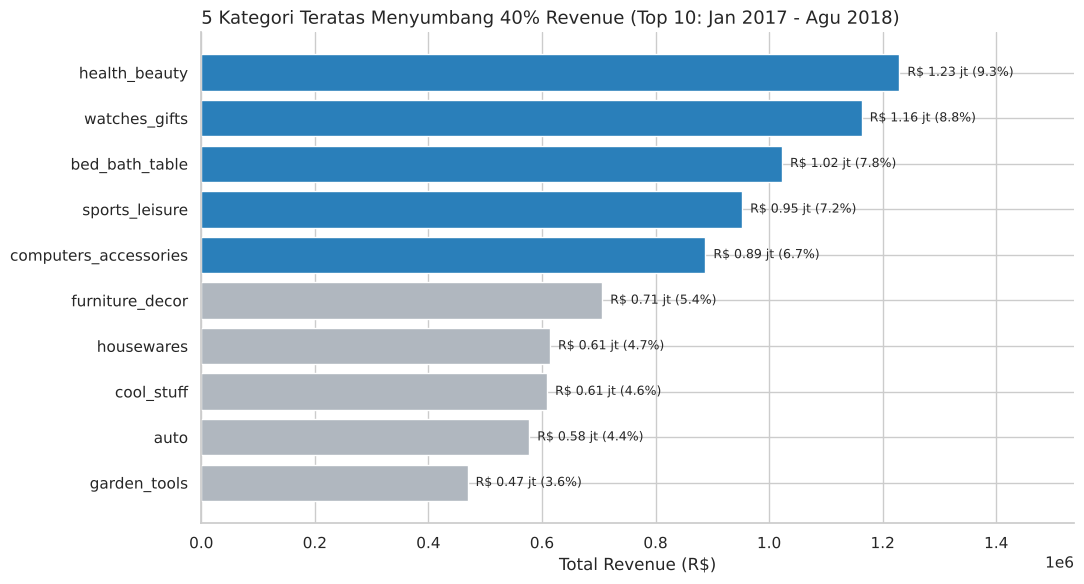

In [15]:
top10 = category_rev.head(10)
top5_share = top10["revenue_share_pct"].head(5).sum()
colors = ["#2a7fba"] * 5 + ["#b0b7bf"] * 5   # 5 teratas disorot, sisanya abu-abu

fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(top10["product_category_name_english"], top10["total_revenue"], color=colors)
ax.invert_yaxis()                              # terbesar di atas
for i, (rev, pct) in enumerate(zip(top10["total_revenue"], top10["revenue_share_pct"])):
    ax.text(rev, i, f"  R$ {rev/1e6:.2f} jt ({pct:.1f}%)", va="center", fontsize=9)
ax.set_title(f"5 Kategori Teratas Menyumbang {top5_share:.0f}% Revenue (Top 10: Jan 2017 - Agu 2018)", fontsize=13, loc="left")
ax.set_xlabel("Total Revenue (R$)")
ax.set_ylabel("")
ax.set_xlim(0, top10["total_revenue"].max() * 1.25)   # sumbang dimulai dari 0
sns.despine()
plt.tight_layout()
plt.show()

**Pilihan visualisasi & prinsip desain:** *line chart* dipakai karena data berupa deret waktu. Sumbu y dimulai dari 0 agar kenaikan tidak tampak berlebihan, dan titik puncak diberi anotasi.

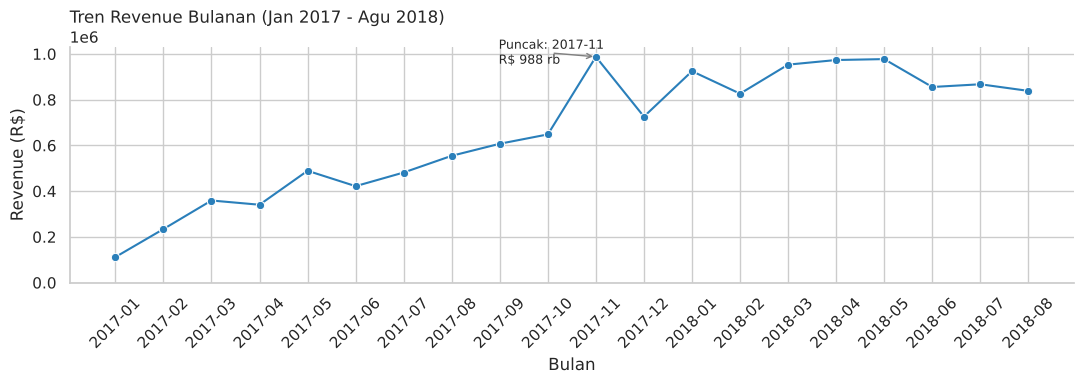

In [16]:
peak = monthly_rev.loc[monthly_rev["revenue"].idxmax()]

fig, ax = plt.subplots(figsize=(11, 4))
sns.lineplot(data=monthly_rev, x="order_month", y="revenue", marker="o", color="#2a7fba", ax=ax)
ax.annotate(f"Puncak: {peak['order_month']}\nR$ {peak['revenue']/1e3:.0f} rb",
            (peak["order_month"], peak["revenue"]), textcoords="offset points", xytext=(-70, -5),
            arrowprops=dict(arrowstyle="->", color="gray"), fontsize=9)
ax.set_ylim(bottom=0)
ax.set_title("Tren Revenue Bulanan (Jan 2017 - Agu 2018)", loc="left")
ax.set_xlabel("Bulan"); ax.set_ylabel("Revenue (R$)")
plt.xticks(rotation=45)
sns.despine()
plt.tight_layout()
plt.show()

### Pertanyaan 2: Keterlambatan pengiriman dan review score

**Pilihan visualisasi & prinsip desain:** panel kiri memakai *bar chart* untuk membandingkan persentase keterlambatan antar state, dengan garis putus-putus sebagai pembanding rata-rata nasional dan 5 state tertinggi disorot merah. Panel kanan membandingkan dua kelompok dengan sumbu y 0-5 (skala penuh review) agar selisih skor tidak dilebih-lebihkan. Warna hijau/merah konsisten menandakan tepat waktu/terlambat.

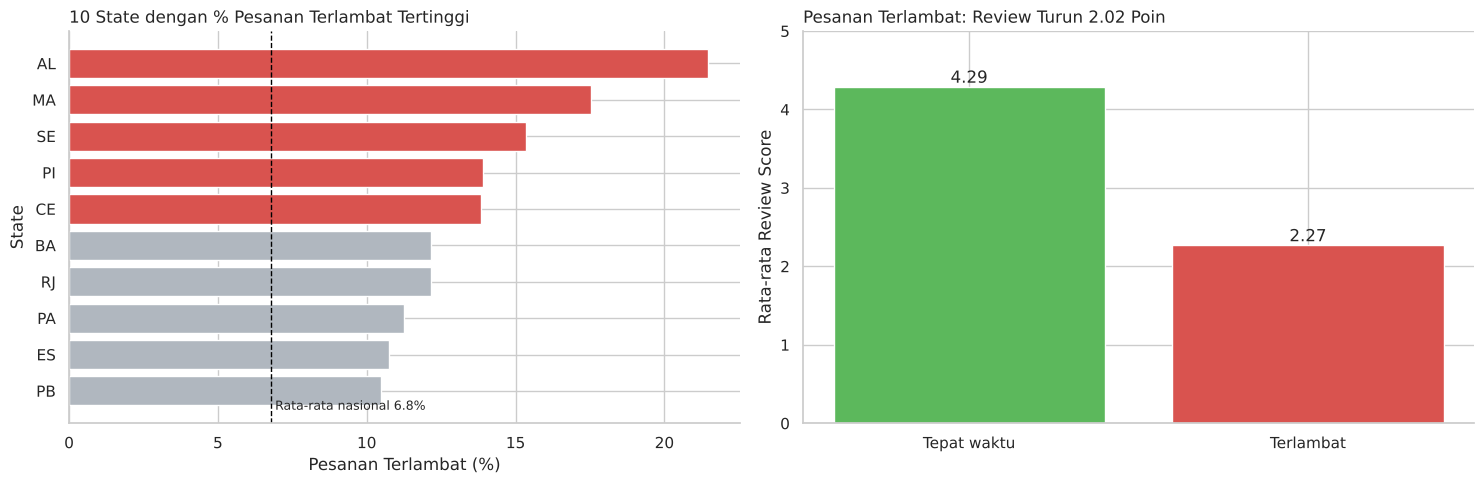

In [17]:
overall_late = order_level["is_late"].mean() * 100
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

top_late = state_stats.head(10)
bar_colors = ["#d9534f"] * 5 + ["#b0b7bf"] * (len(top_late) - 5)
axes[0].barh(top_late["customer_state"], top_late["late_pct"], color=bar_colors)
axes[0].invert_yaxis()
axes[0].axvline(overall_late, color="black", linestyle="--", linewidth=1)
axes[0].text(overall_late, len(top_late) - 0.4, f" Rata-rata nasional {overall_late:.1f}%", fontsize=9, va="bottom")
axes[0].set_title("10 State dengan % Pesanan Terlambat Tertinggi", loc="left")
axes[0].set_xlabel("Pesanan Terlambat (%)"); axes[0].set_ylabel("State")

lv = late_vs_ontime.reset_index()
axes[1].bar(lv["is_late"], lv["avg_review"], color=["#5cb85c", "#d9534f"])
axes[1].set_title(f"Pesanan Terlambat: Review Turun {selisih:.2f} Poin", loc="left")
axes[1].set_xlabel(""); axes[1].set_ylabel("Rata-rata Review Score"); axes[1].set_ylim(0, 5)
for i, v in enumerate(lv["avg_review"]):
    axes[1].text(i, v + 0.05, f"{v:.2f}", ha="center")

sns.despine()
plt.tight_layout()
plt.show()

**Pilihan visualisasi & prinsip desain:** *scatter plot* dipakai untuk melihat hubungan dua variabel numerik (lama kirim vs review) pada tingkat state. Ukuran titik mewakili jumlah pesanan dan setiap titik diberi label agar mudah dibaca. Sumbu tidak dimulai dari 0 karena ini plot hubungan, bukan perbandingan panjang batang.

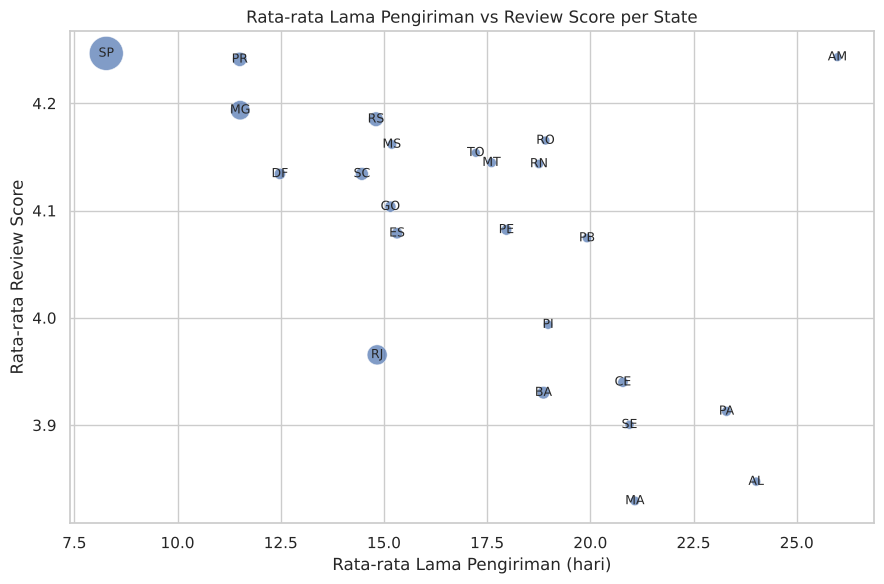

In [18]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=state_stats, x="avg_delivery_days", y="avg_review", size="total_orders",
                sizes=(40, 600), alpha=0.7, legend=False, ax=ax)
for _, r in state_stats.iterrows():
    ax.annotate(r["customer_state"], (r["avg_delivery_days"], r["avg_review"]), fontsize=9, ha="center", va="center")
ax.set_title("Rata-rata Lama Pengiriman vs Review Score per State")
ax.set_xlabel("Rata-rata Lama Pengiriman (hari)"); ax.set_ylabel("Rata-rata Review Score")
plt.tight_layout()
plt.show()

**Insight (Visualization & Explanatory Analysis):**
- Grafik batang menegaskan bahwa 5 kategori teratas saja sudah menyumbang sekitar 40% revenue, sehingga fokus bisnis dapat dipusatkan pada kategori tersebut.
- Grafik tren memperlihatkan lonjakan November 2017 dan pola stabil di 2018, yang menandakan efek musiman akhir tahun.
- Grafik state menunjukkan keterlambatan terkonsentrasi di wilayah timur laut (AL, MA, SE, PI, CE), jauh di atas rata-rata nasional.
- Perbandingan skor dan kelompok keterlambatan menunjukkan review turun drastis begitu pesanan terlambat (4,29 menjadi 3,29 pada telat 1-3 hari, dan 1,70 pada telat >7 hari).

## Analisis Lanjutan (Opsional)

**Tujuan & teknik:** *binning* dengan `pd.cut` mengelompokkan keterlambatan ke dalam rentang (tepat waktu, 1-3, 4-7, >7 hari) untuk melihat apakah penurunan review bersifat bertahap atau tiba-tiba.

In [19]:
# Binning: kelompokkan pesanan berdasarkan lama keterlambatan
bins = [-np.inf, 0, 3, 7, np.inf]
labels = ["Tepat waktu / lebih cepat", "Telat 1-3 hari", "Telat 4-7 hari", "Telat > 7 hari"]
order_level["delay_group"] = pd.cut(order_level["delivery_delay_days"], bins=bins, labels=labels)
delay_group_stats = order_level.groupby("delay_group", observed=True).agg(
    total_orders=("order_id", "count"), avg_review=("review_score", "mean")).reset_index()
delay_group_stats

,delay_group,total_orders,avg_review
0,Tepat waktu / lebih cepat,89672,4.291157
1,Telat 1-3 hari,1869,3.290654
2,Telat 4-7 hari,1802,2.102975
3,Telat > 7 hari,2860,1.696653


**Pilihan visualisasi:** *bar chart* berurutan menurut tingkat keterlambatan, sumbu y 0-5, untuk melihat pola penurunan skor yang bertahap.

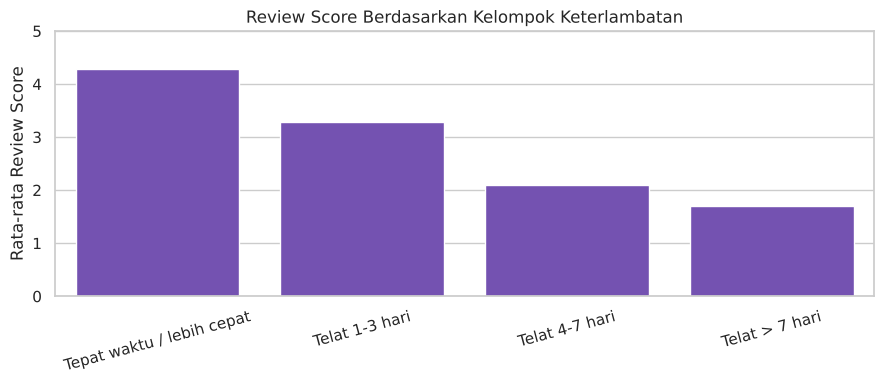

In [20]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=delay_group_stats, x="delay_group", y="avg_review", color="#6f42c1", ax=ax)
ax.set_title("Review Score Berdasarkan Kelompok Keterlambatan")
ax.set_xlabel(""); ax.set_ylabel("Rata-rata Review Score"); ax.set_ylim(0, 5)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## Conclusion

**Kesimpulan Pertanyaan 1 (kategori dengan revenue tertinggi)**
- Dari total revenue R$ 13,18 juta, 10 kategori teratas menyumbang **62,5%**. Lima teratas adalah `health_beauty` (R$ 1,23 jt; 9,3%), `watches_gifts` (R$ 1,16 jt; 8,8%), `bed_bath_table` (R$ 1,02 jt; 7,8%), `sports_leisure` (R$ 0,95 jt; 7,2%), dan `computers_accessories` (R$ 0,89 jt; 6,7%). Kelimanya menyumbang sekitar 40% revenue.
- Pendapatan per pesanan berbeda antar kategori: `watches_gifts` menghasilkan revenue hampir setara `health_beauty` dengan jumlah pesanan jauh lebih sedikit (5.489 vs 8.610), sedangkan `bed_bath_table` punya pesanan terbanyak (9.267) tetapi nilai per pesanan lebih rendah.
- Revenue bulanan tumbuh dari R$ 112 rb (Jan 2017) menjadi puncak R$ 988 rb pada **November 2017** (naik 52% dari bulan sebelumnya, kemungkinan efek Black Friday), lalu stabil di kisaran R$ 0,83-0,98 juta per bulan sepanjang 2018.

**Kesimpulan Pertanyaan 2 (keterlambatan dan review score)**
- Dari 96.203 pesanan, 6.531 pesanan (sekitar 6,8%) terlambat. State dengan persentase keterlambatan tertinggi (minimal 100 pesanan) adalah **AL (21,5%)**, **MA (17,5%)**, **SE (15,4%)**, **PI (13,9%)**, dan **CE (13,8%)**, semuanya di wilayah timur laut. **RJ (12,1%)** juga perlu perhatian karena volumenya besar (12.310 pesanan).
- Rata-rata review score pesanan tepat waktu adalah **4,29**, sedangkan pesanan terlambat hanya **2,27**, selisih **2,02 poin**. Semakin lama terlambat, semakin rendah skornya: 3,29 (telat 1-3 hari), 2,10 (4-7 hari), dan 1,70 (lebih dari 7 hari).
- Korelasi Spearman antara keterlambatan dan review score negatif (-0,18), dan lama pengiriman juga berkorelasi negatif (-0,23). Hubungannya ada tetapi tidak sangat kuat, karena review dipengaruhi faktor lain seperti kualitas produk.
- Keterbatasan: analisis hanya mencakup pesanan *delivered*, dan outlier waktu kirim ekstrem (hingga 209 hari) dipertahankan.

**Rekomendasi (Action Item)**
1. **Prioritaskan kategori teratas**: alokasikan promosi, jaminan stok, dan program seller unggulan pada 5-10 kategori teratas (62,5% revenue). Untuk `watches_gifts` yang nilai per pesanannya tinggi, fokuskan upaya menambah jumlah pesanan.
2. **Siapkan kampanye dan stok menjelang November**, karena puncak revenue terjadi pada November 2017.
3. **Perbaiki logistik di AL, MA, SE, PI, dan CE**: negosiasi ulang mitra ekspedisi atau tambah titik distribusi, serta evaluasi kinerja pengiriman ke RJ karena volumenya besar.
4. **Sesuaikan estimasi pengiriman** di state berisiko tinggi agar lebih realistis dan ekspektasi pelanggan terpenuhi.
5. **Monitor pesanan yang terlambat >3 hari** sebagai peringatan dini: kirim notifikasi proaktif atau kupon kompensasi, karena skor turun tajam (di bawah 2,2) pada keterlambatan lebih dari 3 hari.

In [21]:
# Simpan data bersih untuk dashboard
os.makedirs("dashboard", exist_ok=True)
export_cols = ["order_id", "order_item_id", "price", "freight_value", "product_category_name_english",
               "order_purchase_timestamp", "order_month", "customer_state", "review_score",
               "delivery_time_days", "delivery_delay_days", "is_late"]
main_df[export_cols].to_csv("dashboard/main_data.csv", index=False)
print("main_data.csv tersimpan:", main_df.shape[0], "baris")

main_data.csv tersimpan: 109872 baris
